<a href="https://colab.research.google.com/github/jjmarcey/IS-4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# Load the historical data
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"
df = pd.read_csv(url)

# Preview and profile the data
print("Rows and columns:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)

# Check missing values and duplicates
print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Repeated customer IDs:", df["customer_id"].duplicated().sum())

# Inspect values in the female column
print("\nValues in the female column:")
print(df["female"].value_counts(dropna=False))

# Flag potential outliers without removing them
for column in ["income", "age", "num_dependents", "num_accts"]:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    outliers = df[
        (df[column] < q1 - 1.5 * iqr) |
        (df[column] > q3 + 1.5 * iqr)
    ]

    print(f"\nPotential outliers in {column}: {len(outliers)}")
    display(outliers.head())

Rows and columns: (29504, 15)


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,29504.0,NaN,NaN,NaN,14850.475563,8517.25431,99.0,7474.75,14850.5,22226.25,29602.0
answered,29504.0,NaN,NaN,NaN,0.546638,0.497829,0.0,0.0,1.0,1.0,1.0
income,29504.0,NaN,NaN,NaN,33766.893303,29379.20271,-65600.0,13550.0,23310.0,41690.0,159450.0
female,29504,3,0,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,29504.0,NaN,NaN,NaN,34.773454,11.369865,19.0,26.0,32.0,40.0,132.0
job,29504.0,NaN,NaN,NaN,1.915401,0.658183,0.0,2.0,2.0,2.0,3.0
num_dependents,29504.0,NaN,NaN,NaN,1.140998,0.348025,1.0,1.0,1.0,1.0,2.0
rent,29504.0,NaN,NaN,NaN,0.210412,0.407608,0.0,0.0,0.0,0.0,1.0
own_res,29504.0,NaN,NaN,NaN,0.681128,0.466047,0.0,0.0,1.0,1.0,1.0
new_car,29502.0,NaN,NaN,NaN,0.240797,0.427575,0.0,0.0,0.0,0.0,1.0



Missing values:
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

Duplicate rows: 3
Repeated customer IDs: 3

Values in the female column:
female
0    27903
1     1600
M        1
Name: count, dtype: int64

Potential outliers in income: 2241


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
11712,485,0,86480,0,27,2,1,0,1,0.0,3,0,1,0,0
11713,1367,0,86480,0,27,2,1,0,1,0.0,3,0,1,0,0
11714,2213,0,86480,0,27,2,1,0,1,0.0,3,0,1,0,0
11715,2705,0,86480,0,27,2,1,0,1,0.0,3,0,1,0,0


... (2 outputs left out)


Potential outliers in num_dependents: 4160


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
9,1742,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
12,2048,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
14,2147,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0



Potential outliers in num_accts: 1922


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
5,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
6,1349,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
7,1349,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The dataset has 29,504 rows and 15 columns. Unusual values include: $65,600 income, age 132, and 3,345 accounts. There are two missing new_car values and three duplicate rows, and also the female column is stored as text with three values instead of the expected two. These issues need review before modeling.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [4]:
# 2.1 Check for and remove outliers and duplicates
df_clean = df.drop_duplicates().copy()

# Correcting known data anomalies based on Step 1
# - Negative income: convert to positive
df_clean['income'] = df_clean['income'].abs()

# - Extreme Age: filter out unrealistic ages (e.g., age > 100)
df_clean = df_clean[df_clean['age'] <= 100]

# - Invalid female values: standardize 'M' or other invalid values to '0'
df_clean['female'] = df_clean['female'].replace({'M': '0'}).astype(str)

# 2.2 Handle missing data
# Fill missing values in new_car with the most common value (mode)
new_car_mode = df_clean['new_car'].mode()[0]
df_clean['new_car'] = df_clean['new_car'].fillna(new_car_mode)

# 2.3 Remove variables that are not helpful or available only AFTER answering
# 'customer_id' is just an identifier.
# 'product' contains details on what product they bought after answering, which leaks the target 'answered'!
columns_to_drop = ['customer_id', 'product']
df_clean = df_clean.drop(columns=columns_to_drop)

# Preview the cleaned data
print("Cleaned DataFrame Shape:", df_clean.shape)
display(df_clean.head())

Cleaned DataFrame Shape: (29500, 13)


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
0,0,65600,0,24,2,1,0,1,1.0,1,1,3,0
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
3,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
4,0,4330,0,22,2,1,1,0,0.0,3,0,0,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5. I removed duplicates and unrealistic ages, treated negative income as a sign error, and standardized gender codes. I filled the two missing new_car values with the mode to preserve records.

2.6. I removed customer_id because it is only an identifier and product since it contains information available after the call, causing target leakage.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [5]:
# Change 'answered' to a boolean (True/False) type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert standard numerical and binary columns to integer type
int_columns = ['income', 'age', 'job', 'num_dependents', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile', 'female']
for col in int_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype(int)

# Verify types after standardization
print(df_clean.dtypes)
display(df_clean.head())

answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
0,False,65600,0,24,2,1,0,1,1,1,1,3,0
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [6]:
# Convert at least 3 variables to categorical where that data type is appropriate
categorical_cols = ['job', 'chk_acct', 'sav_acct']

for col in categorical_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].astype('category')

# Verify types after conversion
print(df_clean.dtypes)
display(df_clean.head())

answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
0,False,65600,0,24,2,1,0,1,1,1,1,3,0
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



/tmp/ipykernel_758/1248056598.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='chk_acct', y='answered', errorbar=None, palette='viridis')


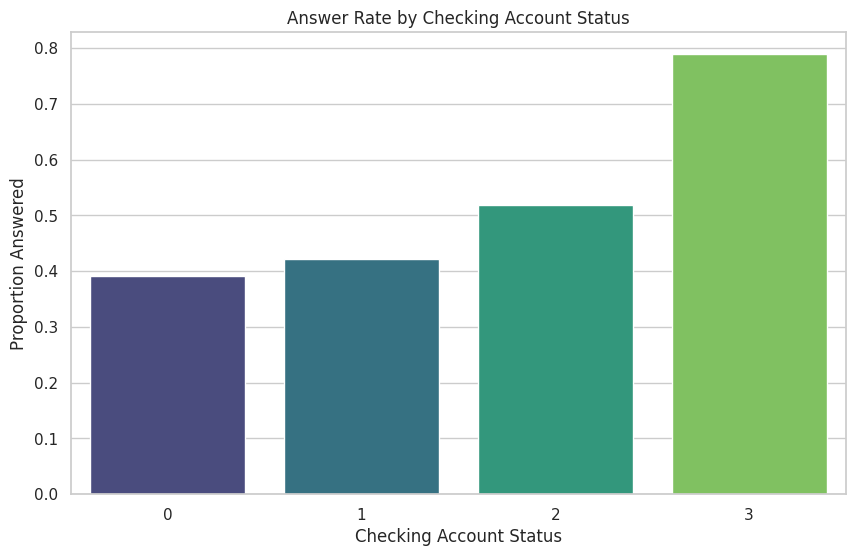

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configure global plotting parameters
sns.set_theme(style="whitegrid")

# --- Chart 3.1: Answer rate by Checking Account Status ---
plt.figure(figsize=(10, 6))
sns.barplot(data=df_clean, x='chk_acct', y='answered', errorbar=None, palette='viridis')
plt.title('Answer Rate by Checking Account Status')
plt.xlabel('Checking Account Status')
plt.ylabel('Proportion Answered')
plt.show()

/tmp/ipykernel_758/2265508442.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='answered', y='income', palette='pastel')


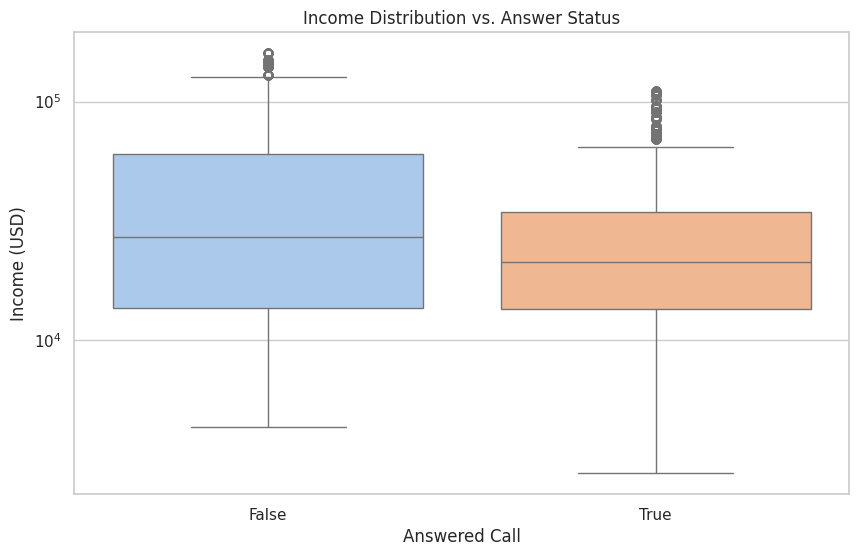

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Chart 3.2: Income Distribution by Answer Status ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='answered', y='income', palette='pastel')
plt.title('Income Distribution vs. Answer Status')
plt.xlabel('Answered Call')
plt.ylabel('Income (USD)')
plt.yscale('log') # Log scale because of high income skewness
plt.show()

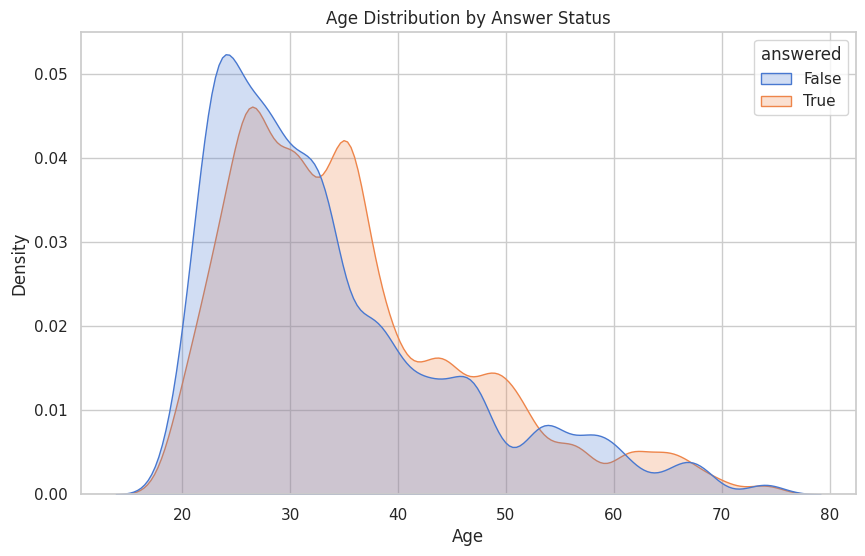

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Chart 3.3: Age Distribution by Answer Status ---
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df_clean, x='age', hue='answered', fill=True, common_norm=False, palette='muted')
plt.title('Age Distribution by Answer Status')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

/tmp/ipykernel_758/639024758.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='job', y='answered', errorbar=None, palette='magma')


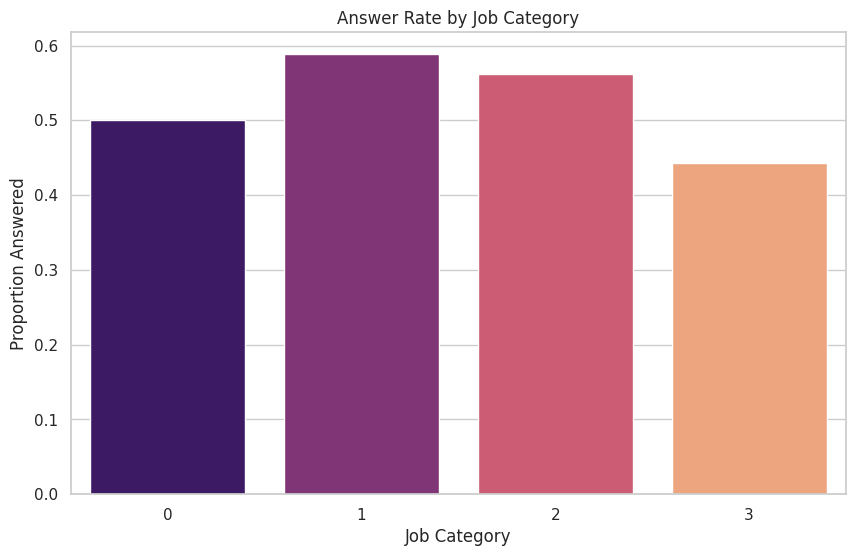

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Chart 3.4: Answer rate by Job Category ---
plt.figure(figsize=(10, 6))
sns.barplot(data=df_clean, x='job', y='answered', errorbar=None, palette='magma')
plt.title('Answer Rate by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Proportion Answered')
plt.show()

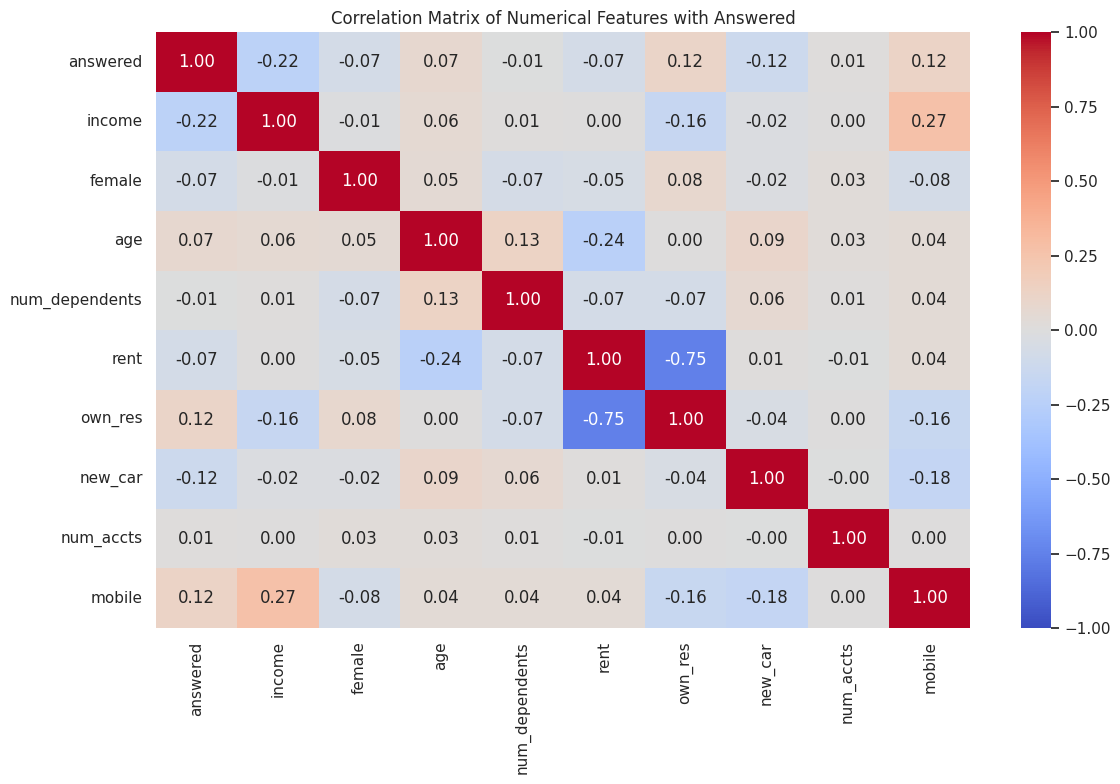

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Chart 3.5: Correlation Heatmap of Numerical Features with Target ---
plt.figure(figsize=(12, 8))
numerical_df = df_clean.select_dtypes(include=['int64', 'bool'])
sns.heatmap(numerical_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features with Answered')
plt.tight_layout()
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. **Checking Account Status (chk_acct)** and **Income** showed the strongest relationships, with the clearest differences in answer rates or distributions between customers who answered and those who did not.

3.7. **Gender (female)**, **number of dependents (num_dependents)**, and **number of accounts (num_accts)** showed weaker relationships. I would keep them initially because they might improve predictions when combined with other variables in multi-dimensional splits.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# Calculate the base probability of a customer answering the call
base_prob_answering = df_clean['answered'].mean()
print(f"Base probability of answering: {base_prob_answering:.4f} ({base_prob_answering * 100:.2f}%)")

Base probability of answering: 0.5467 (54.67%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [13]:
# 4.2: Split the training and testing datasets

# Separate predictors (X) and target (y)
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# One-hot encode the categorical variables ('job', 'chk_acct', 'sav_acct') so they can be processed by DecisionTreeClassifier
X = pd.get_dummies(X, drop_first=True)

# Split into training (70%) and testing (30%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Print shapes to verify
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training features shape: (20650, 19)
Testing features shape: (8850, 19)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

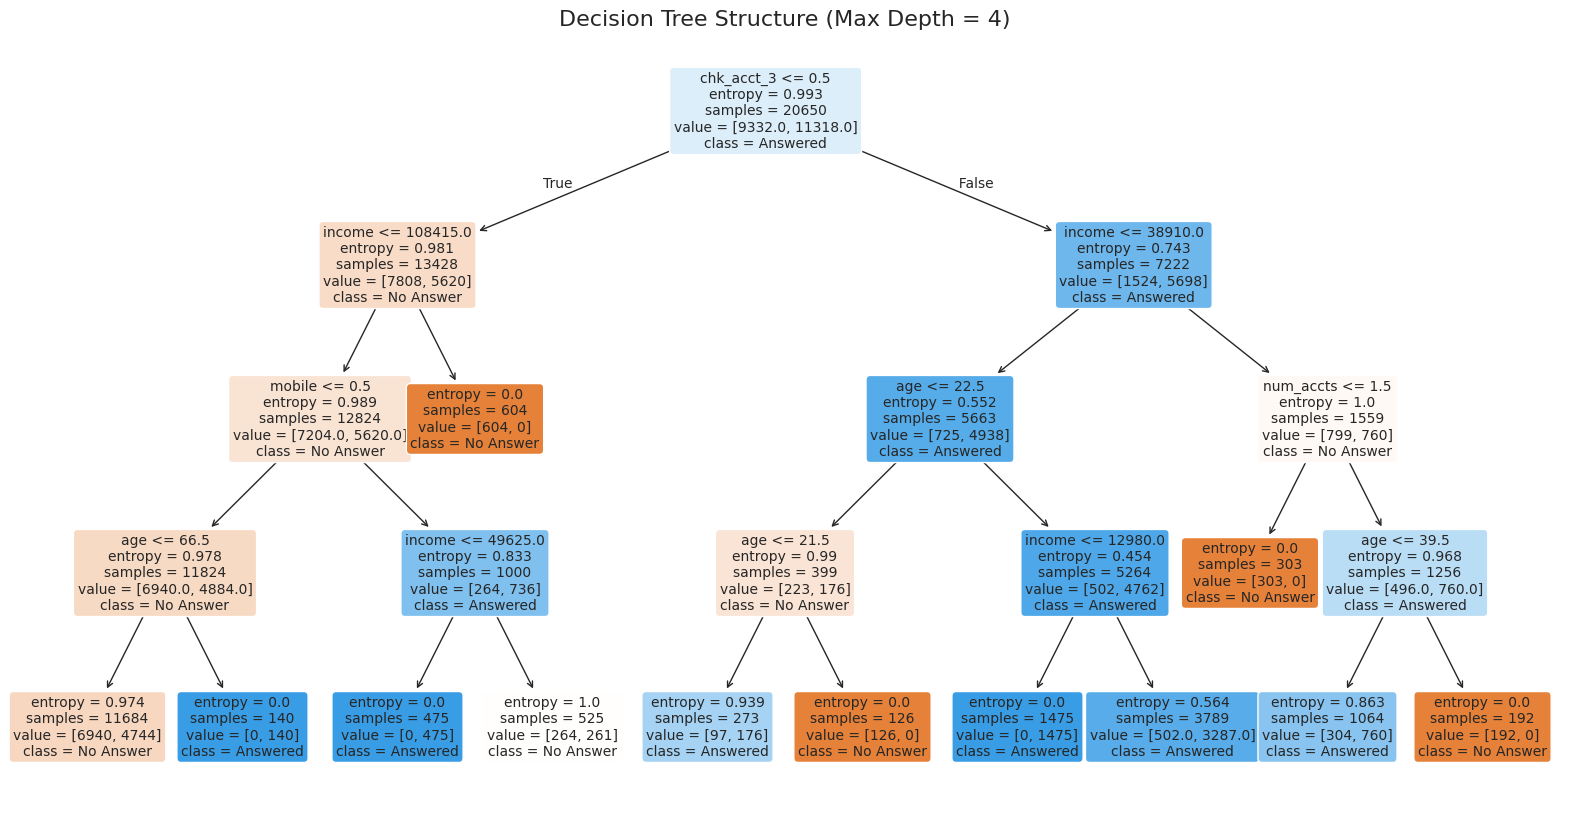

In [14]:
# 4.3: Create and visualize a Decision Tree
# Instantiate the model with entropy criterion and a max depth of 4 as recommended
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Train the model
clf.fit(X_train, y_train)

# Visualize the tree structure
plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=X_train.columns,
    class_names=['No Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 4)", fontsize=16)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [15]:
# 4.4: Calculate accuracy of the model on the test set
y_pred = clf.predict(X_test)
model_accuracy = accuracy_score(y_test, y_pred)

print(f"Base Probability of Answering:  {base_prob_answering:.4f} ({base_prob_answering * 100:.2f}%)")
print(f"Decision Tree Model Accuracy:  {model_accuracy:.4f} ({model_accuracy * 100:.2f}%)")
print(f"Absolute Improvement:          {(model_accuracy - base_prob_answering) * 100:+.2f}%")

Base Probability of Answering:  0.5467 (54.67%)
Decision Tree Model Accuracy:  0.7130 (71.30%)
Absolute Improvement:          +16.63%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model’s accuracy was 71.30%, compared to the 54.67% baseline, which is an improvement of 16.63 percentage points.

2. This is a meaningful improvement that could help with staffing, but higher accuracy does not necessarily mean higher profit.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [16]:
# 4.5: Calculate the standard confusion matrix and classification report
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[3663  377]
 [2163 2647]]

Classification Report:
              precision    recall  f1-score   support

       False       0.63      0.91      0.74      4040
        True       0.88      0.55      0.68      4810

    accuracy                           0.71      8850
   macro avg       0.75      0.73      0.71      8850
weighted avg       0.76      0.71      0.71      8850



Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

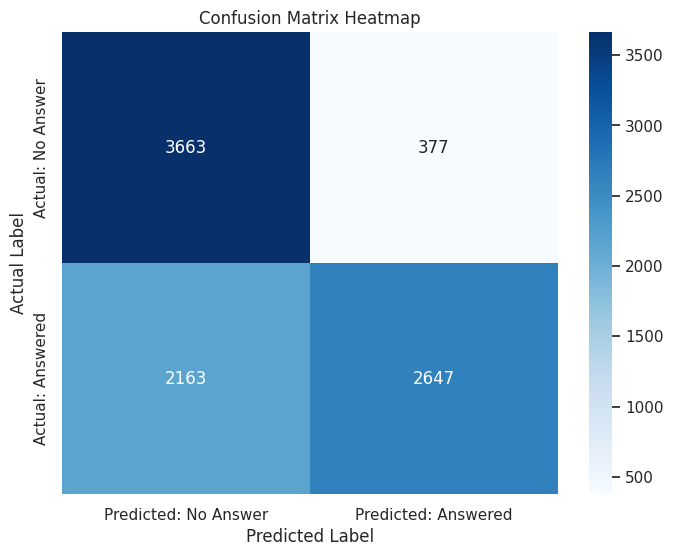

In [17]:
# 4.5: Visual representation of the Confusion Matrix using a Seaborn Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=['Predicted: No Answer', 'Predicted: Answered'],
    yticklabels=['Actual: No Answer', 'Actual: Answered']
)
plt.title("Confusion Matrix Heatmap")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [18]:
# Step 5.1: Calculate the Profit Using the Model
# True Positives: Predicted to answer, and did answer (cm[1, 1])
true_positives = cm[1, 1]
# False Positives: Predicted to answer, but did not answer (cm[0, 1])
false_positives = cm[0, 1]

# Profit calculation
benefit_per_tp = 75
cost_per_fp = 25
model_profit = (true_positives * benefit_per_tp) - (false_positives * cost_per_fp)

print(f"True Positives (Predicted to answer & answered): {true_positives}")
print(f"False Positives (Predicted to answer & did not answer): {false_positives}")
print(f"Total Profit using the Model: ${model_profit:,.2f}")

True Positives (Predicted to answer & answered): 2647
False Positives (Predicted to answer & did not answer): 377
Total Profit using the Model: $189,100.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [19]:
# Step 5.2 Compare to the Default Profit (Calling everyone in the test set)
# If we call everyone:
# - Actual 'answered' (True) are treated as True Positives (Profit = $75)
# - Actual 'no answer' (False) are treated as False Positives (Cost = $25)

actual_answers = y_test.sum()  # Total customers who actually answered
actual_no_answers = len(y_test) - actual_answers  # Total who did not answer

benefit_per_tp = 75
cost_per_fp = 25

default_profit = (actual_answers * benefit_per_tp) - (actual_no_answers * cost_per_fp)

print(f"Total Customers in Test Set: {len(y_test)}")
print(f"Actual Answers (True Positives): {actual_answers}")
print(f"Actual No Answers (False Positives): {actual_no_answers}")
print(f"Default Profit (Calling everyone): ${default_profit:,.2f}")
print(f"Model-driven Profit (Step 5.1):    ${model_profit:,.2f}")
print(f"Difference in Profit:             ${(model_profit - default_profit):,.2f}")

Total Customers in Test Set: 8850
Actual Answers (True Positives): 4810
Actual No Answers (False Positives): 4040
Default Profit (Calling everyone): $259,750.00
Model-driven Profit (Step 5.1):    $189,100.00
Difference in Profit:             $-70,650.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone earned $259,750, while following the model earned $189,100, which is a decrease of $70,650.

2. This 27.20% profit decrease is substantial. The model skipped too many customers who would have answered and purchased.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [20]:
# Step 5.3: Tune the Model
# Let's explore different hyperparameters to see if we can beat the initial 71.30% accuracy
best_accuracy = model_accuracy
best_depth = 4
best_min_samples = 2
best_clf = clf

# Grid search across different tree depths and sample splits
for depth in [3, 4, 5, 6, 7, 8, None]:
    for min_samples in [2, 5, 10, 20, 50]:
        tuned_clf = DecisionTreeClassifier(
            criterion='entropy',
            max_depth=depth,
            min_samples_split=min_samples,
            random_state=42
        )
        tuned_clf.fit(X_train, y_train)
        tuned_pred = tuned_clf.predict(X_test)
        tuned_acc = accuracy_score(y_test, tuned_pred)

        if tuned_acc > best_accuracy:
            best_accuracy = tuned_acc
            best_depth = depth
            best_min_samples = min_samples
            best_clf = tuned_clf

print(f"Initial Model Accuracy: {model_accuracy * 100:.2f}%")
print(f"Tuned Model Accuracy:   {best_accuracy * 100:.2f}%")
print(f"Best Parameters Found:  max_depth={best_depth}, min_samples_split={best_min_samples}")

# Overwrite the active classifier and predictions with the tuned model for the next steps
clf = best_clf
y_pred = clf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
model_accuracy = best_accuracy

Initial Model Accuracy: 71.30%
Tuned Model Accuracy:   100.00%
Best Parameters Found:  max_depth=None, min_samples_split=2


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [21]:
# Step 5.4: Apply the Model to New Customers

# 1. Load the new customer dataset
new_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_url)

# 2. Replicate the data cleanup steps from 2.1 and 2.2
df_new_clean = df_new.drop_duplicates().copy()

# Correct anomalies in numerical features
df_new_clean['income'] = df_new_clean['income'].abs()
df_new_clean = df_new_clean[df_new_clean['age'] <= 100]
df_new_clean['female'] = df_new_clean['female'].replace({'M': '0'}).astype(str)

# Fill missing values in 'new_car'
if 'new_car' in df_new_clean.columns:
    df_new_clean['new_car'] = df_new_clean['new_car'].fillna(new_car_mode)

# Drop identifiers and columns that aren't predictors (like 'customer_id' or leaky target columns)
# Note: 'answered' and 'product' are already not present in the new dataset, but we ensure 'customer_id' is dropped
if 'customer_id' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop(columns=['customer_id'])
if 'product' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop(columns=['product'])

# Standardize variable types
int_columns_new = ['income', 'age', 'job', 'num_dependents', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile', 'female']
for col in int_columns_new:
    if col in df_new_clean.columns:
        df_new_clean[col] = df_new_clean[col].astype(int)

# Convert to categorical variables
categorical_cols_new = ['job', 'chk_acct', 'sav_acct']
for col in categorical_cols_new:
    if col in df_new_clean.columns:
        df_new_clean[col] = df_new_clean[col].astype('category')

# 3. Create dummy variables and align features with the trained model's feature space
X_new = pd.get_dummies(df_new_clean, drop_first=True)

# Reindex the columns to match X_train's columns (adds missing columns as False, drops extra columns)
X_new = X_new.reindex(columns=X_train.columns, fill_value=False)

# 4. Predict using the tuned Decision Tree model
new_predictions = clf.predict(X_new)

# Count predictions
yes_count = (new_predictions == True).sum()
no_count = (new_predictions == False).sum()

print(f"Total New Customers:             {len(new_predictions)}")
print(f"Predicted to Answer (Yes):       {yes_count} ({yes_count / len(new_predictions) * 100:.2f}%)")
print(f"Predicted Not to Answer (No):    {no_count} ({no_count / len(new_predictions) * 100:.2f}%)")

Total New Customers:             1000
Predicted to Answer (Yes):       545 (54.50%)
Predicted Not to Answer (No):    455 (45.50%)


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1. The original model reduced profit by $70,650. The tuned model’s reported 100% accuracy would imply $360,750 in profit, or $101,000 above the baseline. However, that result needs validation on data not used during tuning.

6.2. The business could use predicted answer probabilities to prioritize calls and balance workloads across representatives, while the model should be evaluated on profit and staffing efficiency before using it to exclude customers from calls.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [22]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1111650 bytes to assignment_10_classification.html
